# Retorno causal de un algoritmo de recomendación

**TPI Decision Intelligence Capstone — Estadística Aplicada y Modelos de Regresión (EAyMR 2026, UCA)**

| Integrante | Rol Scrum |
|---|---|
| Verónica López Marsico | Project Lead & Scrum Master |
| Lucía Báez | Backend & ML / Causal Engineer |
| Antonella Robiollio | Frontend & UI/UX + QA & Validation Engineer |

Notebook maestro (anexo del informe Quarto). Semilla global `SEED = 42`; nivel de significancia
fijado a priori α = 0,05. Uso de IA: `docs/ia_log.md`.

**Confidencialidad.** Las reglas de la competencia de Kaggle declaran confidenciales los datos.
Este notebook **nunca muestra registros individuales**: solo agregados, distribuciones y
resultados de contrastes. Los datos se regeneran con `python data/download_data.py`.

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repo por ruta relativa (funciona desde notebooks/, desde la raíz y en CI)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from tpi import graficos as gr
from tpi.aleatorizacion import resumir_rho, rho_intra_busqueda
from tpi.auditoria import (
    agregar_competidores,
    aplicar_centinelas,
    cerca_tukey_log,
    contraste_mcar,
    diagnostico_escala_precio,
    imputar_con_indicador,
    precio_relativo,
    resumen_distribucion,
)
from tpi.config import SEED, set_global_seed
from tpi.contrato import contrato_activo
from tpi.inferencia import (
    anova_un_factor,
    contraste_pareado,
    describir_grupos,
    efecto_minimo_detectable,
    mann_whitney,
    posthoc,
    potencia,
    welch_dos_grupos,
)

warnings.filterwarnings("ignore", category=FutureWarning)
rng = set_global_seed(SEED)
gr.estilo()
pd.set_option("display.precision", 4)
CONTRATO = contrato_activo()
crudo = CONTRATO.cargar()
print(
    f"Contrato: {CONTRATO.nombre} | filas: {len(crudo):,} | búsquedas: {crudo['srch_id'].nunique():,}"
)

Contrato: expedia | filas: 739,323 | búsquedas: 30,000


---
# Fase 1 — Inferencia estadística clásica, diagnósticos y ANOVA

## 1.1 Diseño muestral y plan experimental

**Unidad de observación:** el par búsqueda × hotel $(s, i)$. **Unidad de muestreo:** la
búsqueda $s$. Los hoteles de una lista comparten usuario, fecha y destino, así que sus filas
no son independientes: muestrear filas sueltas rompería las listas y, en la Fase 3, filtraría
información entre Train y Test. Muestreamos 15.000 búsquedas completas por estrato de
`random_bool` (R), con semilla fija.

**Unidades independientes para los contrastes.** Todo contraste se hace sobre unidades
independientes: búsquedas (contrastes pareados dentro de la búsqueda) o reservas (a lo sumo
una por búsqueda). Nunca sobre filas, que darían errores estándar artificialmente chicos.

**Nivel de significancia y potencia.** Fijamos α = 0,05 antes de mirar los datos. Con miles de
unidades, cualquier diferencia minúscula es "significativa": por eso cada contraste reporta el
tamaño de efecto y el **efecto mínimo detectable** con potencia $1-\beta = 0{,}80$, que dice qué
puede y qué no puede ver la muestra.

In [2]:
busq = crudo.groupby("srch_id").agg(
    R=("random_bool", "first"),
    n_hoteles=("prop_id", "size"),
    reservas=("booking_bool", "sum"),
    clics=("click_bool", "sum"),
)
tabla_diseno = busq.groupby("R").agg(
    busquedas=("n_hoteles", "size"),
    filas=("n_hoteles", "sum"),
    hoteles_por_lista=("n_hoteles", "mean"),
    pct_con_reserva=("reservas", lambda s: 100 * (s >= 1).mean()),
    pct_con_clic=("clics", lambda s: 100 * (s >= 1).mean()),
)
tabla_diseno

,busquedas,filas,hoteles_por_lista,pct_con_reserva,pct_con_clic
R,,,,,
0,15000,376197,25.0798,94.16,100.0
1,15000,363126,24.2084,13.14,100.0


**Slots estructurales.** La cobertura media de las listas (hoteles observados / posición máxima)
es ≈ 0,87. Antes de atribuirlo a una remoción de filas, miramos en qué fracción de las búsquedas
aparece cada posición.

In [3]:
presencia = (
    crudo[crudo.position <= 30].groupby(["random_bool", "position"]).size().unstack(0)
    / crudo.groupby("random_bool")["srch_id"].nunique()
).rename(columns={0: "R = 0", 1: "R = 1"})
SLOTS_ESPECIALES = presencia.index[presencia.max(axis=1) < 0.2].tolist()
print("Posiciones presentes en < 20 % de las búsquedas:", SLOTS_ESPECIALES)
presencia.loc[[p for p in range(1, 13)]].T.round(3)

Posiciones presentes en < 20 % de las búsquedas: [5, 11, 17, 23]


position,1,2,3,4,5,6,7,8,9,10,11,12
random_bool,,,,,,,,,,,,
R = 0,1.000,1.000,0.999,0.957,0.062,0.998,0.978,0.956,0.935,0.855,0.074,0.897
R = 1,0.995,0.995,0.995,0.990,0.016,0.993,0.969,0.944,0.923,0.897,0.017,0.882


Las posiciones 5, 11, 17 y 23 (un slot cada seis) aparecen en apenas 6-8 % de las búsquedas con
R = 0 y 1,4-1,7 % con R = 1, contra ≈ 99 % de sus vecinas. Son **slots fijos ocupados por listados
que no están en el dataset** (por ejemplo, anuncios u ofertas especiales), y explican casi todo el
13 % de posiciones faltantes. Consecuencias:

* El hueco es **estructural**, no una remoción de hoteles según sus atributos. Por lo tanto **no
  explica** la asociación residual posición–atributo observada con R = 1 (`docs/ia_log.md`,
  error 10), que sigue abierta.
* $T = 1\{\text{position} \le 5\}$ se mantiene definido sobre la posición **en pantalla** (así la
  define Kaggle), pero en la práctica el top-5 contiene casi siempre 4 hoteles del dataset
  (posiciones 1-4): el quinto slot lo ocupa otro listado.
* Las filas que sí ocupan esos slots son pocas y atípicas (tasa de clic muy baja, ver 1.5). Se
  conservan, pero se señalan con un indicador.

## 1.2 Auditoría forense de datos

Auditamos la génesis de cada anomalía y cuantificamos la distorsión antes y después del
tratamiento. Cuatro familias: **centinelas**, **desplazamiento de escala del precio**,
**valores extremos** y **faltantes** (sección 1.3).

### Centinelas

Tres variables usan el 0 como código de "no hay dato": `prop_review_score` (hotel sin reseñas),
`prop_starrating` (sin categoría) y `prop_log_historical_price` (sin ventas en el período
previo). Tratarlas como valores reales sesga medias y desvíos. Las pasamos a NaN y conservamos un
indicador binario, porque la ausencia de información es en sí misma una señal para el ranker y
para el usuario.

In [4]:
df, tabla_centinelas = aplicar_centinelas(crudo)
df["slot_especial"] = df["position"].isin(SLOTS_ESPECIALES).astype("int8")  # ver 1.1
tabla_centinelas

,centinela,pct_filas,media_antes,media_despues,sesgo_media_pct,desvio_antes,desvio_despues
variable,,,,,,,
prop_review_score,0.0,5.1705,3.7577,3.9629,-5.1792,1.0822,0.6495
prop_starrating,0.0,3.3731,3.1859,3.2972,-3.3731,1.0504,0.8804
prop_log_historical_price,0.0,14.8256,4.3048,5.0541,-14.8256,1.8601,0.5248


### Desplazamiento de escala del precio

`price_usd` debería ser el precio por noche y por habitación. Lo verificamos con la única
fuente externa disponible, el gasto real de las reservas:

$$r^{\text{noche}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{noches} \cdot \text{habitaciones}}, \qquad
  r^{\text{estadía}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{habitaciones}}.$$

Si el precio es por noche, $r^{\text{noche}} \approx 1{,}1$ (impuestos y tasas). Si es por
estadía, $r^{\text{estadía}} \approx 1{,}1$. Con una noche ambas coinciden, así que las usamos
para calibrar la banda de tolerancia, y clasificamos solo las estadías de dos o más noches.

In [5]:
reservas_1n = df[
    (df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.srch_length_of_stay == 1)
]
r1 = reservas_1n.gross_bookings_usd / (reservas_1n.price_usd * reservas_1n.srch_room_count)
print(
    "Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón:",
    r1.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).tolist(),
)
escala = diagnostico_escala_precio(df)
tabla_escala = escala["escala"].value_counts().to_frame("reservas")
tabla_escala["pct"] = 100 * tabla_escala["reservas"] / tabla_escala["reservas"].sum()
por_sitio = escala.groupby("site_id").agg(
    n=("escala", "size"), pct_por_estadia=("escala", lambda s: 100 * (s == "por_estadia").mean())
)
print(
    "Sitios con ≥ 100 reservas: % por estadía entre",
    por_sitio.query("n >= 100").pct_por_estadia.min().round(2),
    "y",
    por_sitio.query("n >= 100").pct_por_estadia.max().round(2),
)
tabla_escala

Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón: [0.95, 1.102, 1.134, 1.19, 1.509]
Sitios con ≥ 100 reservas: % por estadía entre 1.87 y 7.48


,reservas,pct
escala,,
por_noche,7225,87.4591
incompatible,771,9.3330
por_estadia,265,3.2078


### Valores extremos de precio

Dos reglas complementarias:

* **Absoluta:** cercas extremas de Tukey sobre $\log(\text{precio})$, $[Q_1 - 3\,\mathrm{IQR},\; Q_3 + 3\,\mathrm{IQR}]$.
  Detecta búsquedas enteras con precios imposibles, que la regla relativa no ve porque la
  mediana de la búsqueda también es absurda.
* **Relativa:** precio mayor que 10 veces (o menor que 1/10 de) la mediana de su búsqueda.

**Variable de trabajo:** precio relativo a la mediana de la búsqueda (winsorizado en los
percentiles 1 y 99) y su logaritmo. Es invariante a cualquier escala común de la lista (por
noche vs. por estadía, moneda) y mide lo que el usuario ve: si el hotel es caro *para esa
búsqueda*.

In [6]:
df = precio_relativo(df)
lo_abs, hi_abs = cerca_tukey_log(df["price_usd"])
print(
    f"Cercas absolutas: [{lo_abs:.2f}; {hi_abs:.2f}] USD | outliers: {df.precio_outlier.sum():,} filas ({100 * df.precio_outlier.mean():.3f} %)"
)
distorsion = pd.DataFrame(
    {
        "price_usd (crudo)": resumen_distribucion(df["price_usd"]),
        "price_usd sin outliers": resumen_distribucion(df.loc[df.precio_outlier == 0, "price_usd"]),
        "log precio relativo": resumen_distribucion(df["log_precio_rel"]),
    }
).T
distorsion

Cercas absolutas: [8.41; 1951.14] USD | outliers: 1,445 filas (0.195 %)


,n,media,desvio,asimetria,p50,p99,max
price_usd (crudo),739323.0,237.6314,10152.1004,237.0404,125.0,639.0000,4.1217e+06
price_usd sin outliers,737878.0,157.1369,119.6814,3.6310,125.0,611.1723,1.9500e+03
log precio relativo,739323.0,0.0106,0.3932,0.2854,0.0,1.1888,1.1888e+00


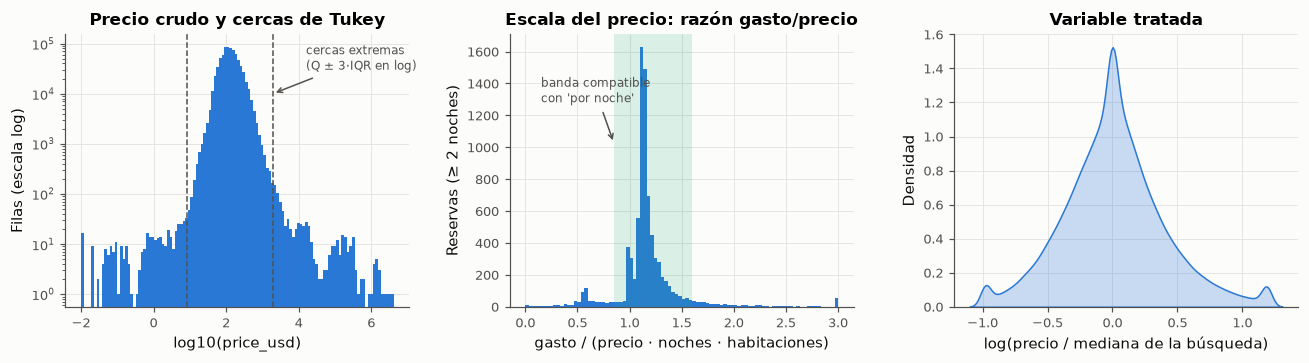

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
lp = np.log10(df["price_usd"].clip(lower=0.01))
ax[0].hist(lp, bins=120, color=gr.AZUL)
for c in (lo_abs, hi_abs):
    ax[0].axvline(np.log10(c), color=gr.TEXTO_2, ls="--", lw=1)
ax[0].set(
    yscale="log",
    xlabel="log10(price_usd)",
    ylabel="Filas (escala log)",
    title="Precio crudo y cercas de Tukey",
)
ax[0].annotate(
    "cercas extremas\n(Q ± 3·IQR en log)",
    xy=(np.log10(hi_abs), 1e4),
    xytext=(4.2, 3e4),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
razones = escala["razon_noche"].clip(0, 3)
ax[1].hist(razones, bins=90, color=gr.AZUL)
ax[1].axvspan(0.85, 1.6, color=gr.AQUA, alpha=0.15, lw=0)
ax[1].set(
    xlabel="gasto / (precio · noches · habitaciones)",
    ylabel="Reservas (≥ 2 noches)",
    title="Escala del precio: razón gasto/precio",
)
ax[1].annotate(
    "banda compatible\ncon 'por noche'",
    xy=(0.85, ax[1].get_ylim()[1] * 0.6),
    xytext=(0.15, ax[1].get_ylim()[1] * 0.75),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
sns.kdeplot(df["log_precio_rel"], ax=ax[2], color=gr.AZUL, fill=True, alpha=0.25, bw_adjust=1.5)
ax[2].set(
    xlabel="log(precio / mediana de la búsqueda)", ylabel="Densidad", title="Variable tratada"
)
fig.tight_layout()
gr.guardar(fig, "f1_precio_auditoria")
plt.show()

## 1.3 Mecanismo de pérdida de datos (MCAR, MAR, MNAR)

Sea $R_j = 1\{X_j \text{ falta}\}$. **MCAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j)$.
**MAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j \mid X_{\text{obs}})$. **MNAR**: depende del propio valor
faltante. MCAR implica que $R_j$ es independiente de **toda** variable observada, y eso es
contrastable: comparamos $R_j$ contra variables observadas (χ² de independencia para binarias,
Mann-Whitney para continuas, Bonferroni por familia). MAR vs. MNAR **no** es contrastable con
los datos: se argumenta por el mecanismo de generación.

Con cientos de miles de filas, casi cualquier dependencia da p ≈ 0. Por eso la lectura se apoya
en el tamaño de efecto: $|\text{SMD}| \ge 0{,}1$ o $V \ge 0{,}1$ es dependencia apreciable.

In [8]:
faltantes = (
    df[[c for c in df.columns if df[c].isna().any() and not c.startswith("comp")]]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("pct_faltante")
)
faltantes

,pct_faltante
gross_bookings_usd,97.8230
visitor_hist_starrating,95.5182
visitor_hist_adr_usd,95.5143
srch_query_affinity_score,94.2999
orig_destination_distance,32.8042
prop_location_score2,22.0433
prop_log_historical_price,14.8256
prop_review_score,5.3376
prop_starrating,3.3731


In [9]:
CONTRA = [
    "booking_bool",
    "click_bool",
    "random_bool",
    "prop_starrating",
    "log_precio_rel",
    "prop_location_score1",
    "srch_booking_window",
]
mcar = pd.concat(
    [
        contraste_mcar(df, c, [v for v in CONTRA if v != c])
        for c in [
            "prop_location_score2",
            "orig_destination_distance",
            "prop_review_score",
            "visitor_hist_starrating",
            "srch_query_affinity_score",
        ]
    ]
)
resumen_mcar = mcar.pivot(index="variable_faltante", columns="contra", values="efecto").round(3)
resumen_mcar["max_|efecto|"] = resumen_mcar.abs().max(axis=1)
resumen_mcar

contra,booking_bool,click_bool,log_precio_rel,prop_location_score1,prop_starrating,random_bool,srch_booking_window,max_|efecto|
variable_faltante,,,,,,,,
orig_destination_distance,0.001,0.007,0.019,0.229,0.304,0.024,0.196,0.304
prop_location_score2,0.043,0.050,-0.030,-0.506,-0.257,0.019,-0.104,0.506
prop_review_score,0.020,0.016,-0.000,-0.238,-0.049,0.050,0.146,0.238
srch_query_affinity_score,0.014,0.000,0.014,0.132,0.180,0.082,0.112,0.180
visitor_hist_starrating,0.014,0.000,0.003,-0.012,-0.080,0.072,0.091,0.091


**Lectura (efectos de la tabla; ver `contraste_mcar` para p-valores con Bonferroni):**

| Variable | % faltante | Dependencia observada | Mecanismo | Tratamiento |
|---|---|---|---|---|
| `prop_location_score2` | 22,0 | SMD = −0,506 con `location_score1`; −0,257 con estrellas; V = 0,043 con reserva | **MAR**: el faltante se explica por variables observadas del hotel (hoteles peor ubicados y de menos estrellas) | Mediana por país + indicador `_faltante` |
| `orig_destination_distance` | 32,8 | SMD = 0,304 con estrellas; 0,229 con `location_score1`; 0,196 con anticipación | **MAR**: falla de geolocalización asociada a perfiles observables | Mediana por par (país del usuario, país del hotel) + indicador |
| `prop_review_score` (incl. centinela 0) | 5,3 | SMD = −0,238 con `location_score1`; 0,146 con anticipación | **MNAR estructural**: el hotel no tiene reseñas; el valor no existe | Mediana por estrellas + indicador `sin_resenas`, que conserva la información |
| `visitor_hist_starrating` / `_adr_usd` | 95,5 | Todas las dependencias < 0,1 (máx. 0,091) | **MNAR estructural**: el usuario no tiene compras previas; no hay valor que imputar | **No se imputa**: se usa `usuario_recurrente` |
| `srch_query_affinity_score` | 94,3 | SMD = 0,180 con estrellas | **MNAR estructural**: el hotel no apareció en búsquedas previas | **No se imputa**: indicador `con_afinidad` |
| `gross_bookings_usd` | 97,8 | Existe solo si `booking_bool = 1` | Estructural por diseño | Solo se analiza entre reservas |

**MCAR se rechaza para las cinco variables contrastadas** (en todas hay al menos una dependencia
con p ajustado < 0,05), aunque para `visitor_hist_starrating` ninguna dependencia es apreciable.
La imputación por mediana dentro de grupos es coherente con MAR condicional al grupo, y el
indicador evita que el modelo trate el valor imputado como observado. Un faltante MNAR
estructural **no se imputa**: imputar un historial que no existe inventaría información.

In [10]:
df["usuario_recurrente"] = df["visitor_hist_starrating"].notna().astype("int8")
df["con_afinidad"] = df["srch_query_affinity_score"].notna().astype("int8")
df = imputar_con_indicador(df, "prop_location_score2", por=["prop_country_id"])
df = imputar_con_indicador(df, "prop_review_score", por=["prop_starrating"])
df = imputar_con_indicador(df, "prop_starrating")
df = imputar_con_indicador(df, "prop_log_historical_price", por=["prop_country_id"])
df = imputar_con_indicador(
    df, "orig_destination_distance", por=["visitor_location_country_id", "prop_country_id"]
)
print(
    "NaN restantes en variables de ajuste:",
    int(
        df[
            [
                "prop_location_score2",
                "prop_review_score",
                "prop_starrating",
                "prop_log_historical_price",
                "orig_destination_distance",
            ]
        ]
        .isna()
        .sum()
        .sum()
    ),
)

NaN restantes en variables de ajuste: 0


## 1.4 Variables de competidores ($Z_c$): ¿confusor o predictor?

**Criterio (fijado por el equipo antes del análisis):** $Z_c$ es **confusor** si el ranking la usa
($Z_c \to T$) **y** además afecta la reserva ($Z_c \to Y$); si solo afecta $Y$, es
**predictor** (no hace falta para bloquear caminos de puerta trasera, aunque reduce varianza).

* **$Z_c \to T$:** el orden aleatorio (R = 1) corta los arcos que entran a T, así que la
  asociación intra-búsqueda entre posición y $Z_c$ con R = 0 *por encima* de la de R = 1 es la
  parte que aporta el ranker.
* **$Z_c \to Y$:** con R = 1 la posición es (casi) aleatoria; una regresión logística de la
  reserva (y del clic, su mediador obligado) sobre $Z_c$, controlando por $\log(\text{posición})$
  y por calidad y precio del hotel, con errores robustos por clúster de búsqueda, mide el efecto
  de $Z_c$ sobre $Y$.

Los 8 competidores tienen entre 56 % y 98 % de faltantes. Los resumimos en variables que no
dependen del signo de `compN_rate`: competidores con dato (`comp_n_info`), saldo de
comparaciones (`comp_saldo`) y máxima diferencia porcentual válida (`comp_diff_max`).

In [11]:
df = agregar_competidores(df)
df["log_pos"] = np.log(df["position"])
filas_zc = []
for v in ["comp_n_info", "comp_saldo", "comp_diff_max"]:
    r0 = resumir_rho(rho_intra_busqueda(df[df.random_bool == 0], v), v)
    r1 = resumir_rho(rho_intra_busqueda(df[df.random_bool == 1], v), v)
    d1 = df[df.random_bool == 1].dropna(subset=[v])
    fila = {
        "variable": v,
        "rho_R0": r0.rho_medio,
        "rho_R1": r1.rho_medio,
        "rho_R0_menos_R1": r0.rho_medio - r1.rho_medio,
    }
    for y in ["click_bool", "booking_bool"]:
        f = smf.logit(
            f"{y} ~ {v} + log_pos + prop_starrating + prop_review_score + log_precio_rel", d1
        ).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d1["srch_id"]})
        fila[f"OR_{y}"] = float(np.exp(f.params[v]))
        fila[f"p_{y}"] = float(f.pvalues[v])
    filas_zc.append(fila)
tabla_zc = pd.DataFrame(filas_zc).set_index("variable")
tabla_zc

,rho_R0,rho_R1,rho_R0_menos_R1,OR_click_bool,p_click_bool,OR_booking_bool,p_booking_bool
variable,,,,,,,
comp_n_info,-0.0986,-0.0332,-0.0654,0.9949,2.0328e-01,1.1182,2.9066e-17
comp_saldo,-0.0372,0.0074,-0.0446,1.1467,2.0649e-08,1.1371,4.1392e-02
comp_diff_max,-0.0157,-0.0012,-0.0146,1.0002,7.9140e-01,0.9985,5.3444e-01


**Clasificación (criterio fijado por Verónica; aplicación de Claude Code, a revisar):**

* `comp_n_info` (cuántos competidores tienen dato): **confusor**. El ranker la usa (ρ̄ intra-búsqueda
  −0,099 con R = 0 vs. −0,033 con R = 1) y afecta la reserva con la posición aleatoria (OR = 1,118
  por competidor adicional, p = 2,9·10⁻¹⁷).
* `comp_saldo` (saldo de comparaciones de precio): **confusor**. El ranker la usa (−0,037 vs.
  +0,007) y afecta la reserva (OR = 1,137 por unidad de saldo, p = 0,041) y el clic (OR = 1,147,
  p = 2,1·10⁻⁸).
* `comp_diff_max` (máxima diferencia porcentual): **ni confusor ni predictor útil**. Su
  asociación con la posición es menor que el margen de ±0,03 (−0,016 vs. −0,001) y no se rechaza
  H0 de efecto sobre la reserva (p = 0,53) ni sobre el clic (p = 0,79).

$Z_c = \{$`comp_n_info`, `comp_saldo`$\}$ entra al conjunto de ajuste de Backdoor en la Fase 4.
Esta clasificación no depende del signo de `compN_rate`; su **interpretación** (si "+1" significa
que Expedia es más barata) requiere la definición textual de Kaggle, pendiente de transcribir de la
pestaña Data.

## 1.5 Análisis exploratorio univariado y bivariado

La figura central del problema: la tasa de clic por posición con el orden del algoritmo
(R = 0) y con el orden aleatorio (R = 1). Bajo R = 1 la caída con la posición es **sesgo de
posición** puro (el arco $T \to M$). Bajo R = 0 se le suma la calidad de los hoteles que el
algoritmo pone arriba (confusión). La distancia entre ambas curvas es la primera evidencia
visual del sesgo que la Fase 4 tiene que corregir.

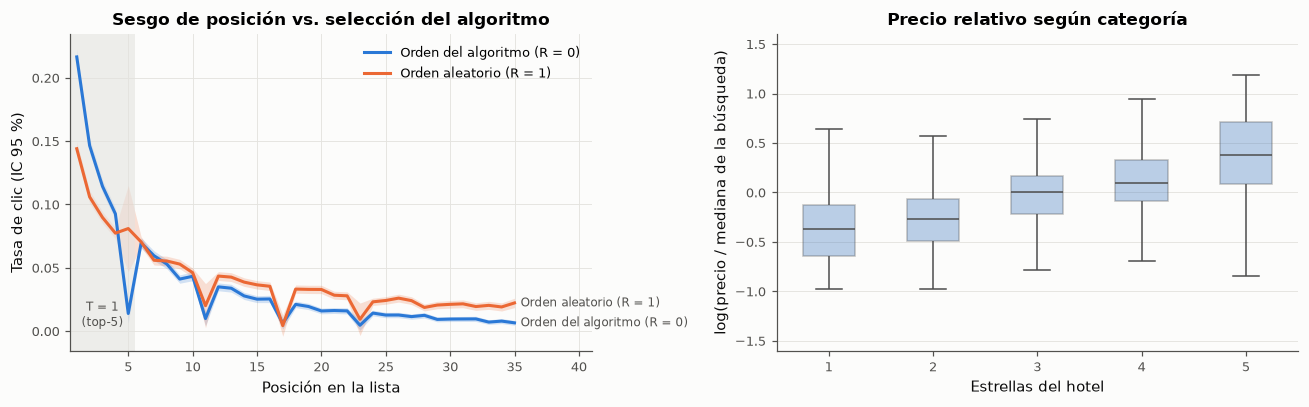

In [12]:
ctr = (
    df[df.position <= 35]
    .groupby(["random_bool", "position"])["click_bool"]
    .agg(["mean", "count"])
    .reset_index()
)
ctr["ee"] = np.sqrt(ctr["mean"] * (1 - ctr["mean"]) / ctr["count"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r, color, nombre in [
    (0, gr.AZUL, "Orden del algoritmo (R = 0)"),
    (1, gr.NARANJA, "Orden aleatorio (R = 1)"),
]:
    d = ctr[ctr.random_bool == r]
    ax[0].plot(d.position, d["mean"], color=color, label=nombre)
    ax[0].fill_between(
        d.position, d["mean"] - 1.96 * d.ee, d["mean"] + 1.96 * d.ee, color=color, alpha=0.2, lw=0
    )
    ax[0].annotate(
        nombre,
        xy=(d.position.iloc[-1], d["mean"].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        fontsize=8,
        color=gr.TEXTO_2,
        va="center",
    )
ax[0].axvspan(0.5, 5.5, color=gr.GRILLA, alpha=0.6, lw=0)
ax[0].text(3, 0.004, "T = 1\n(top-5)", ha="center", fontsize=8, color=gr.TEXTO_2)
ax[0].set(
    xlabel="Posición en la lista",
    ylabel="Tasa de clic (IC 95 %)",
    title="Sesgo de posición vs. selección del algoritmo",
    xlim=(0.5, 41),
)
ax[0].legend(loc="upper right")
grupos_est = df.dropna(subset=["prop_starrating"]).assign(
    estrellas=lambda d: d.prop_starrating.astype(int).astype(str)
)
sns.boxplot(
    data=grupos_est,
    x="estrellas",
    y="log_precio_rel",
    order=["1", "2", "3", "4", "5"],
    color=gr.AZUL,
    ax=ax[1],
    fliersize=0,
    width=0.5,
    boxprops={"alpha": 0.35},
)
ax[1].set(
    xlabel="Estrellas del hotel",
    ylabel="log(precio / mediana de la búsqueda)",
    title="Precio relativo según categoría",
    ylim=(-1.6, 1.6),
)
fig.tight_layout()
gr.guardar(fig, "f1_ctr_posicion")
plt.show()

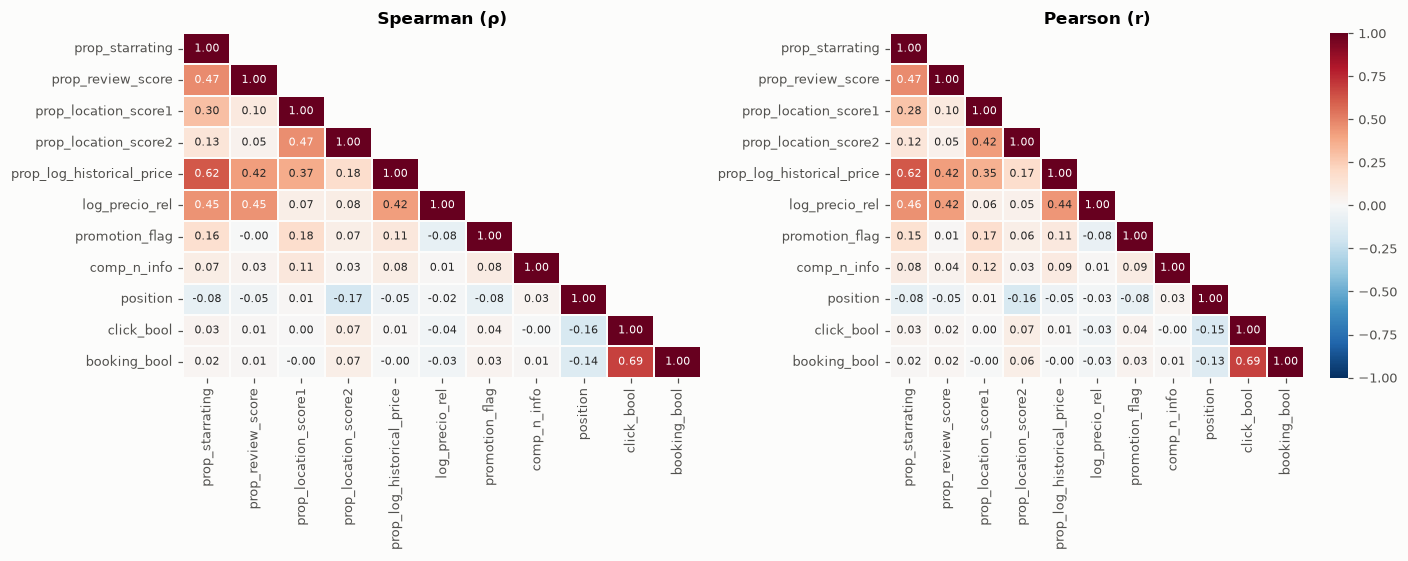

Mayor |ρ_Spearman − r_Pearson|: {('prop_location_score2', 'prop_location_score1'): 0.043, ('prop_location_score1', 'prop_location_score2'): 0.043, ('prop_review_score', 'log_precio_rel'): 0.03}


,ρ con position,ρ con booking_bool
prop_starrating,-0.082,0.017
prop_review_score,-0.045,0.013
prop_location_score1,0.013,-0.004
prop_location_score2,-0.172,0.065
prop_log_historical_price,-0.054,-0.000
log_precio_rel,-0.023,-0.032
promotion_flag,-0.082,0.032
comp_n_info,0.029,0.013
click_bool,-0.160,0.686


In [13]:
NUM = [
    "prop_starrating",
    "prop_review_score",
    "prop_location_score1",
    "prop_location_score2",
    "prop_log_historical_price",
    "log_precio_rel",
    "promotion_flag",
    "comp_n_info",
    "position",
    "click_bool",
    "booking_bool",
]
corr_s = df[NUM].corr(method="spearman")
corr_p = df[NUM].corr(method="pearson")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
mascara = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
for a, c, t in [(ax[0], corr_s, "Spearman (ρ)"), (ax[1], corr_p, "Pearson (r)")]:
    sns.heatmap(
        c,
        mask=mascara,
        cmap=gr.DIVERGENTE,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        linewidths=1,
        linecolor=gr.SUPERFICIE,
        cbar=a is ax[1],
        ax=a,
    )
    a.set_title(t)
    a.grid(False)
fig.tight_layout()
gr.guardar(fig, "f1_correlaciones")
plt.show()
print(
    "Mayor |ρ_Spearman − r_Pearson|:",
    (corr_s - corr_p).abs().stack().sort_values(ascending=False).head(3).round(3).to_dict(),
)
pd.DataFrame(
    {"ρ con position": corr_s["position"], "ρ con booking_bool": corr_s["booking_bool"]}
).drop(["position", "booking_bool"]).round(3)

**Lectura de la exploración:**

* **Sesgo de posición.** Con orden aleatorio, la tasa de clic cae con la posición (el arco
  $T \to M$ existe). Con el orden del algoritmo, la curva arranca más alta en el top-5 y cae más
  abajo al final de la lista: el algoritmo concentra arriba a los hoteles que se clickean igual.
  La brecha entre curvas es la confusión que la Fase 4 debe eliminar. Los "pozos" en 5, 11, 17 y
  23 son los slots estructurales (1.1).
* **Calidad y precio.** El precio relativo sube con las estrellas: calidad y precio están
  entrelazados, lo que anticipa multicolinealidad en la Fase 2.
* **Correlaciones.** Spearman y Pearson difieren a lo sumo en 0,043 (entre los dos scores de
  ubicación), así que las relaciones son aproximadamente monótonas y lineales en estas escalas. La
  variable más asociada a la posición es `prop_location_score2` (ρ = −0,172: mejor ubicación, más
  arriba), seguida por el clic (−0,160), las estrellas (−0,082) y la promoción (−0,082). Con la
  reserva, la asociación más fuerte es el clic (ρ = 0,686, el mediador), seguida por la posición
  (ρ = −0,14 en la matriz). Las demás son débiles (`location_score2`: 0,065).
* **Colinealidad anticipada.** `prop_log_historical_price` correlaciona 0,62 con las estrellas, y
  el precio relativo, 0,45 con estrellas y con reseñas: bloque calidad–precio a auditar con VIF en
  la Fase 2.
* Son correlaciones a nivel fila, sin separar R = 0 de R = 1: descriptivas, no causales.

## 1.6 Contraste 1 — Sesgo de posición en el clic (pareado, R = 1)

**Pregunta de negocio:** si el orden es aleatorio, ¿los hoteles del top-5 reciben más clics que
el resto *de la misma lista*? Es el primer eslabón del DAG ($T \to M$): si no existiera, el slot
no tendría valor causal.

Para cada búsqueda $s$ con R = 1: $D_s = \overline{\text{CTR}}_{s,\text{top-5}} - \overline{\text{CTR}}_{s,\text{resto}}$.

$$H_0: \mathbb{E}[D_s] = 0 \qquad H_1: \mathbb{E}[D_s] \neq 0$$

**Estadístico:** t de Student para una muestra sobre las diferencias pareadas,
$t = \bar D / (s_D/\sqrt{n})$ con $n-1$ gl. Es pareado porque las dos tasas comparten búsqueda
(usuario, destino, fecha), lo que elimina todo confusor a nivel búsqueda. La validez descansa en
el TCL ($n$ en miles); como resguardo no paramétrico, Wilcoxon de rangos con signo. Tamaño de
efecto: $d_z = \bar D / s_D$.

**Selección:** el dataset solo trae búsquedas con al menos un clic (BITÁCORA, Entrada 4). Eso
infla ambas tasas, pero dentro de la búsqueda el cociente se conserva aproximadamente, así que
también reportamos el cociente de tasas medias.

In [14]:
r1_df = df[df.random_bool == 1]
por_busq = (
    r1_df.assign(T=(r1_df.position <= 5)).groupby(["srch_id", "T"])["click_bool"].mean().unstack()
)
por_busq = por_busq.dropna()
D = por_busq[True] - por_busq[False]
c1 = contraste_pareado(D, nombre="Contraste 1 (CTR top-5 − resto, R = 1)")
print(c1.texto())
print(f"Wilcoxon: W = {c1.extra['wilcoxon_W']:.4g}, p = {c1.extra['wilcoxon_p']:.3g}")
print(
    f"CTR medio top-5 = {por_busq[True].mean():.4f} | resto = {por_busq[False].mean():.4f} | cociente = {por_busq[True].mean() / por_busq[False].mean():.3f}"
)
print(
    f"Efecto mínimo detectable (d_z, 1−β = 0,80): {efecto_minimo_detectable(len(D)):.4f} | potencia para el d_z observado: {potencia(c1.efecto, len(D)):.4f}"
)
print(f"Asimetría de D: {stats.skew(D):.3f} | curtosis en exceso: {stats.kurtosis(D):.3f}")

Contraste 1 (CTR top-5 − resto, R = 1): t(14982) = 37.47, p = 7.74e-294, IC 95 % [0.05313; 0.05899], d_z = 0.306 (α = 0.05) → se rechaza H0
Wilcoxon: W = 4.326e+07, p = 7.7e-131
CTR medio top-5 = 0.1043 | resto = 0.0483 | cociente = 2.161
Efecto mínimo detectable (d_z, 1−β = 0,80): 0.0229 | potencia para el d_z observado: 1.0000
Asimetría de D: -0.540 | curtosis en exceso: 3.608


**Decisión.** Se rechaza $H_0$: t(14982) = 37,47, p = 7,74·10⁻²⁹⁴. Con orden aleatorio, los hoteles
del top-5 tienen una tasa de clic 5,6 puntos porcentuales mayor que el resto de su propia lista
(IC 95 % [5,31; 5,90] p.p.), y $d_z = 0{,}306$ (efecto pequeño a mediano en la escala de Cohen). El
Wilcoxon de resguardo coincide (p = 7,7·10⁻¹³¹), así que la conclusión no depende de la
normalidad: $D_s$ tiene asimetría −0,540 y curtosis en exceso 3,608, que el TCL absorbe con
n = 14.983.

**Escala relativa.** La tasa de clic media del top-5 es 0,1043 contra 0,0483 del resto: un
cociente de **2,16**. Por la selección del dataset (solo búsquedas con clic) las tasas absolutas
están infladas, pero el cociente dentro de la búsqueda es la escala que se conserva (Entrada 4).

**Potencia.** Con n = 14.983 el efecto mínimo detectable es $d_z$ = 0,023: la muestra detectaría
efectos 13 veces menores que el observado.

**Negocio.** Sin mirar la calidad del hotel, estar en el top-5 duplica la probabilidad de clic.
Ese es el valor *bruto* del slot sobre la atención; falta saber cuánto se traduce en reservas
(Fase 4).

## 1.7 Contraste 2 — Gasto por reserva: usuarios recurrentes vs. nuevos

**Pregunta de negocio:** ¿los usuarios con historial de compras en Expedia (recurrentes) gastan
más por reserva que los nuevos? Es la "autoselección de usuarios recurrentes" del enunciado: si
gastan distinto, el historial ($Z_u$) es candidato a confusor de cualquier efecto sobre el gasto.

**Unidad:** la reserva (a lo sumo una por búsqueda, así que son independientes). Excluimos
reservas con gasto nulo y con precio outlier. **Variable:** $\log(\text{gasto})$, porque el
gasto tiene cola pesada a derecha; la diferencia de medias en log se lee como **cociente de
medias geométricas** $e^{\bar y_1 - \bar y_2}$.

$$H_0: \mu_{\log,\text{recurrentes}} = \mu_{\log,\text{nuevos}} \qquad H_1: \mu_{\log,\text{recurrentes}} \neq \mu_{\log,\text{nuevos}}$$

**Estadístico:** t de Welch, porque los grupos tienen tamaños muy distintos y no hay razón para
suponer varianzas iguales (Levene abajo). Gl de Welch-Satterthwaite. Resguardo: U de Mann-Whitney
($H_0$: $P(X_1 > X_2) = 1/2$). Tamaños de efecto: g de Hedges y r biserial de rangos.
Contraste **descriptivo**, no causal: los recurrentes difieren en destino y duración.

In [15]:
res = df[(df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.precio_outlier == 0)].copy()
res["log_gasto"] = np.log(res["gross_bookings_usd"])
rec, nue = (
    res.loc[res.usuario_recurrente == 1, "log_gasto"],
    res.loc[res.usuario_recurrente == 0, "log_gasto"],
)
lev = stats.levene(rec, nue, center="median")
print(f"Levene (Brown-Forsythe): F(1; {len(res) - 2}) = {lev.statistic:.4g}, p = {lev.pvalue:.3g}")
c2 = welch_dos_grupos(rec, nue, nombre="Contraste 2 (log gasto, recurrentes − nuevos)")
c2b = mann_whitney(np.exp(rec), np.exp(nue), nombre="Contraste 2b (gasto, Mann-Whitney)")
print(c2.texto())
print(c2b.texto())
print(
    f"Cociente de medias geométricas = {np.exp(c2.diferencia):.4f}, IC 95 % [{np.exp(c2.ic95[0]):.4f}; {np.exp(c2.ic95[1]):.4f}]"
)
print(f"Hodges-Lehmann (diferencia de gasto en USD): {c2b.diferencia:.2f}")
print(
    f"n recurrentes = {len(rec)}, n nuevos = {len(nue)} | efecto mínimo detectable (g): {efecto_minimo_detectable(len(rec), len(nue)):.4f}"
)
print(f"Asimetría log gasto: recurrentes {stats.skew(rec):.3f}, nuevos {stats.skew(nue):.3f}")
res.groupby("usuario_recurrente")["gross_bookings_usd"].describe()

Levene (Brown-Forsythe): F(1; 16062) = 3.19, p = 0.0741
Contraste 2 (log gasto, recurrentes − nuevos): t(1158.6) = 1.303, p = 0.193, IC 95 % [-0.0194; 0.09617], g de Hedges = 0.043 (α = 0.05) → no se rechaza H0
Contraste 2b (gasto, Mann-Whitney): U = 7.949e+06, p = 0.0931, r biserial de rangos = 0.031 (α = 0.05) → no se rechaza H0
Cociente de medias geométricas = 1.0391, IC 95 % [0.9808; 1.1009]
Hodges-Lehmann (diferencia de gasto en USD): 8.59
n recurrentes = 1025, n nuevos = 15039 | efecto mínimo detectable (g): 0.0904


Asimetría log gasto: recurrentes 0.076, nuevos 0.507


,count,mean,std,min,25%,50%,75%,max
usuario_recurrente,,,,,,,,
0,15039.0,383.0831,527.8447,3.94,125.205,222.48,431.545,10432.6396
1,1025.0,389.4037,430.0935,1.38,126.340,236.83,460.200,3368.4199


**Decisión.** No se rechaza $H_0$: t de Welch(1158,6) = 1,303, p = 0,193; IC 95 % para la diferencia
de medias en log [−0,019; 0,096]. Equivale a un cociente de medias geométricas de 1,039 (IC 95 %
[0,981; 1,101]): los recurrentes gastarían entre 1,9 % menos y 10,1 % más por reserva. El
Mann-Whitney de resguardo coincide (p = 0,093; r biserial = 0,031).

**Supuestos.** Levene no rechaza la igualdad de varianzas (F(1; 16062) = 3,19, p = 0,074), pero
Welch se mantiene porque los grupos están muy desbalanceados (1.025 vs. 15.039), y en ese caso un
error de tipo II de Levene sería costoso. La asimetría del log gasto (0,076 y 0,507) está dentro
de $[-1, 1]$.

**Potencia.** No rechazar no prueba igualdad. Con estos tamaños, el efecto mínimo detectable con
potencia 0,80 es g = 0,090; el observado (g = 0,043) es la mitad. **Diferencias de gasto menores
que ≈ 0,09 desvíos no son detectables con esta muestra**: el contraste es compatible tanto con
"no hay diferencia" como con una diferencia chica.

**Negocio.** No hay evidencia de que el historial del usuario cambie el ticket medio. La
"autoselección de recurrentes" del enunciado, si existe, operaría sobre la conversión y no sobre
el gasto por reserva.

## 1.8 ANOVA de un factor — Precio por noche del hotel reservado según categoría

**Pregunta:** ¿el precio esperado por noche del hotel reservado varía entre categorías de
estrellas? Es la base del supuesto de que la calidad ($Z_h$) y el precio están entrelazados en
$Z$ (relevante para la multicolinealidad de la Fase 2).

**Modelo:** $Y_{gj} = \mu + \alpha_g + \varepsilon_{gj}$, con $\sum \alpha_g = 0$, $Y$ = log del
precio por noche de la reserva $j$ en la categoría $g \in \{1\text{–}2, 3, 4, 5\}$ (1 y 2
estrellas se unen por el bajo $n$ de 1 estrella).

$$H_0: \mu_{1\text{–}2} = \mu_3 = \mu_4 = \mu_5 \qquad H_1: \exists\, g \ne g' : \mu_g \ne \mu_{g'}$$

**Supuestos y resguardos:**
* *Normalidad:* con miles de observaciones, Shapiro-Wilk rechaza ante desvíos microscópicos
  irrelevantes para el TCL. La evaluamos con asimetría (criterio $|\text{asimetría}| \le 1$),
  curtosis y gráficos Q-Q.
* *Homocedasticidad:* Levene centrado en la mediana (Brown-Forsythe). Si se rechaza, el F
  clásico deja de ser válido y usamos **ANOVA de Welch** (no asume varianzas iguales) y
  **Kruskal-Wallis** (no paramétrico).
* *Post-hoc:* Games-Howell (no asume varianzas iguales), comparado con Tukey HSD (que sí las
  asume) y con Welch por pares + Bonferroni (conservador).

In [16]:
anova_df = res.dropna(subset=["prop_starrating"]).copy()
anova_df = anova_df[anova_df.precio_outlier == 0]
anova_df["categoria"] = pd.cut(
    anova_df.prop_starrating, [0, 2, 3, 4, 5], labels=["1-2", "3", "4", "5"]
)
anova_df["log_precio_noche"] = np.log(anova_df.price_usd)
desc = describir_grupos(anova_df, "log_precio_noche", "categoria")
sw = {
    g: stats.shapiro(d.sample(min(len(d), 5000), random_state=SEED)).pvalue
    for g, d in anova_df.groupby("categoria", observed=True)["log_precio_noche"]
}
desc["shapiro_p (n≤5000)"] = pd.Series(sw)
desc

,n,media,desvio,asimetria,curtosis_exceso,shapiro_p (n≤5000)
categoria,,,,,,
1-2,2301,4.3216,0.3960,0.2050,1.6134,7.5852e-17
3,6662,4.6435,0.4198,-0.2133,1.4907,2.3968e-22
4,5849,4.9337,0.4709,-0.0250,0.7798,3.0058e-10
5,1252,5.2964,0.4994,0.3139,0.4907,3.3613e-05


In [17]:
an = anova_un_factor(anova_df, "log_precio_noche", "categoria")
for k in ["levene", "clasico", "welch", "kruskal"]:
    print(an[k].texto())
print(f"ω² (ANOVA clásico) = {an['clasico'].extra['omega2']:.4f}")
ph = posthoc(anova_df, "log_precio_noche", "categoria")
ph["cociente_precios"] = np.exp(ph["diferencia"])
ph

Levene (Brown-Forsythe): F(3; 16060) = 56.57, p = 2.27e-36, razón de varianzas máx/mín = 1.590 (α = 0.05) → se rechaza H0
ANOVA clásico: F(3; 16060) = 1820, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
ANOVA de Welch: F(3; 4432.0) = 1807, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
Kruskal-Wallis: H(3) = 4150, p < 1e-300 (subdesborde de doble precisión), ε² = 0.258 (α = 0.05) → se rechaza H0
ω² (ANOVA clásico) = 0.2536


,A,B,diferencia,ee,p_games_howell,p_bonferroni,p_tukey,rechaza_games_howell,rechaza_bonferroni,rechaza_tukey,cociente_precios
0,1-2,3,-0.3218,0.0097,0.0000e+00,7.2874e-213,0.0,True,True,True,0.7248
1,1-2,4,-0.6121,0.0103,0.0000e+00,0.0000e+00,0.0,True,True,True,0.5422
2,1-2,5,-0.9748,0.0164,0.0000e+00,0.0000e+00,0.0,True,True,True,0.3773
3,3,4,-0.2902,0.0080,3.9457e-13,4.0669e-271,0.0,True,True,True,0.7481
4,3,5,-0.6529,0.0150,3.7637e-13,2.0205e-272,0.0,True,True,True,0.5205
5,4,5,-0.3627,0.0154,2.1061e-13,4.4095e-106,0.0,True,True,True,0.6958


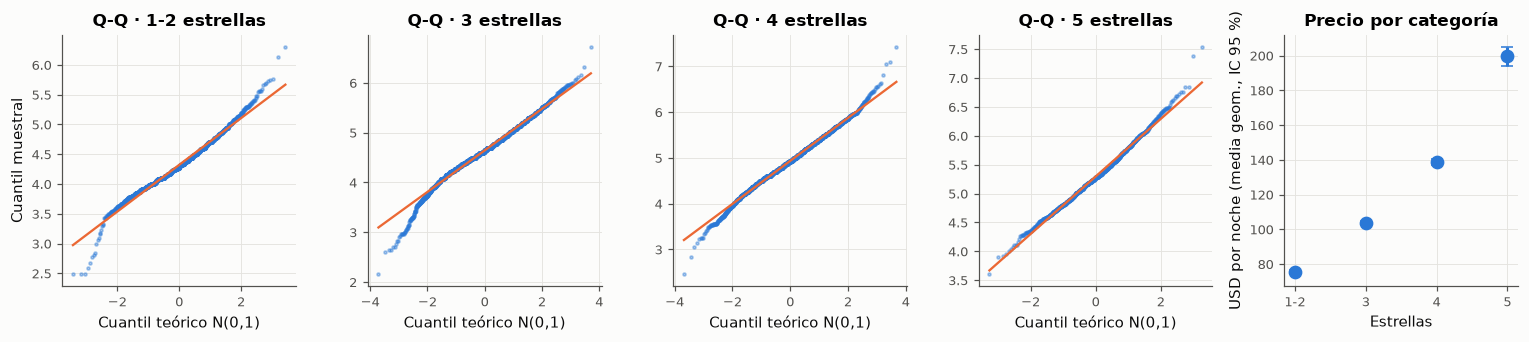

In [18]:
fig, ax = plt.subplots(1, 5, figsize=(14, 3.2))
for a, (g, d) in zip(
    ax[:4], anova_df.groupby("categoria", observed=True)["log_precio_noche"], strict=True
):
    stats.probplot(d, dist="norm", plot=a)
    a.get_lines()[0].set(markerfacecolor=gr.AZUL, markeredgecolor=gr.AZUL, markersize=2, alpha=0.4)
    a.get_lines()[1].set(color=gr.NARANJA, lw=1.5)
    a.set(
        title=f"Q-Q · {g} estrellas",
        xlabel="Cuantil teórico N(0,1)",
        ylabel="Cuantil muestral" if g == "1-2" else "",
    )
medias = anova_df.groupby("categoria", observed=True)["log_precio_noche"].agg(["mean", "sem"])
ax[4].errorbar(
    range(len(medias)),
    np.exp(medias["mean"]),
    yerr=[
        np.exp(medias["mean"]) - np.exp(medias["mean"] - 1.96 * medias["sem"]),
        np.exp(medias["mean"] + 1.96 * medias["sem"]) - np.exp(medias["mean"]),
    ],
    fmt="o",
    color=gr.AZUL,
    capsize=4,
    ms=8,
)
ax[4].set(
    xticks=range(len(medias)),
    xticklabels=medias.index,
    xlabel="Estrellas",
    ylabel="USD por noche (media geom., IC 95 %)",
    title="Precio por categoría",
)
fig.tight_layout()
gr.guardar(fig, "f1_anova")
plt.show()

**Supuestos.**
* *Normalidad:* Shapiro-Wilk rechaza en los cuatro grupos (p entre 2,4·10⁻²² y 3,4·10⁻⁵ con n ≤ 5.000),
  como anticipa el enunciado para muestras grandes. Lo relevante: asimetrías entre −0,213 y 0,314
  (dentro de $[-1, 1]$) y curtosis en exceso entre 0,49 y 1,61. Los Q-Q muestran colas algo más
  pesadas que la normal, sobre todo la izquierda en 1-2 y 3 estrellas. Con n ≥ 1.252 por grupo, el
  TCL garantiza la validez aproximada de las medias.
* *Homocedasticidad:* **Levene rechaza** (F(3; 16060) = 56,57, p = 2,27·10⁻³⁶; razón de varianzas
  máx/mín = 1,59). El F clásico pierde validez, así que la inferencia principal es el **ANOVA de
  Welch**.

**Decisión.** Se rechaza $H_0$ con las tres pruebas: Welch F(3; 4432,0) = 1807; F clásico(3; 16060)
= 1820; Kruskal-Wallis H(3) = 4150; en las tres, p < 10⁻³⁰⁰ (subdesborde de doble precisión). El
tamaño de efecto es grande: η² = 0,254, ω² = 0,254 y ε² = 0,258. La categoría explica ≈ 25 % de
la varianza del log precio.

**Post-hoc.** Las seis comparaciones son significativas con los tres criterios (Games-Howell,
Tukey HSD y Bonferroni), así que la conclusión no depende del supuesto de homocedasticidad. En
cocientes de medias geométricas, un hotel de 5 estrellas cuesta 2,65 veces uno de 1-2
(1/0,3773), 1,92 veces uno de 3 y 1,44 veces uno de 4. Los p-valores de Games-Howell que aparecen
como ≈ 10⁻¹³ o 0 son el límite numérico de la distribución de rango estudentizado en pingouin, no
valores exactos.

**Por qué Welch y no Kruskal-Wallis como principal:** la pregunta es sobre el **valor esperado**
del log precio (medias), y Welch responde exactamente eso sin suponer varianzas iguales.
Kruskal-Wallis contrasta otra hipótesis (dominancia estocástica) y queda como resguardo.

## 1.9 Síntesis de la Fase 1

| Hallazgo | Evidencia | Consecuencia para las fases siguientes |
|---|---|---|
| Hay sesgo de posición puro sobre el clic | Contraste 1: CTR ×2,16 en el top-5 con orden aleatorio | El arco $T \to M$ existe; el efecto sobre la reserva se estima en la Fase 4 |
| El algoritmo selecciona hoteles que se clickean igual | Curvas de CTR R = 0 vs. R = 1 | Confusión a corregir (Backdoor) |
| La categoría explica ≈ 25 % del log precio | ANOVA de Welch, η² = 0,254 | Multicolinealidad calidad–precio (VIF, Fase 2) |
| El gasto por reserva no difiere entre recurrentes y nuevos (no detectable bajo g ≈ 0,09) | Contraste 2 | $Z_u$ entra como confusor de la conversión, no del gasto |
| $Z_c$ = {`comp_n_info`, `comp_saldo`} son confusores | Tabla 1.4 | Entran al ajuste en la Fase 4 |
| Slots estructurales 5/11/17/23 fuera del dataset | Presencia por posición | T = top-5 en pantalla ≈ 4 hoteles del dataset |
| Faltantes MAR y MNAR estructurales, ninguno MCAR | Tabla 1.3 | Imputación por grupo + indicadores; los MNAR no se imputan |